In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [2]:
plt.style.use("ggplot")

In [3]:
df = pd.read_csv("email.csv")

In [4]:
df.columns

Index(['Category', 'Message'], dtype='str')

In [5]:
df["Category"].value_counts()

Category
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64

In [6]:
df.drop_duplicates(inplace = True)

In [9]:
df = df.iloc[:-1]

In [10]:
df.tail(2)

,Category,Message
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [11]:
df["Category"].value_counts()

Category
ham     4516
spam     641
Name: count, dtype: int64

In [12]:
df["Category"].value_counts(normalize = True)*100

Category
ham     87.570293
spam    12.429707
Name: proportion, dtype: float64

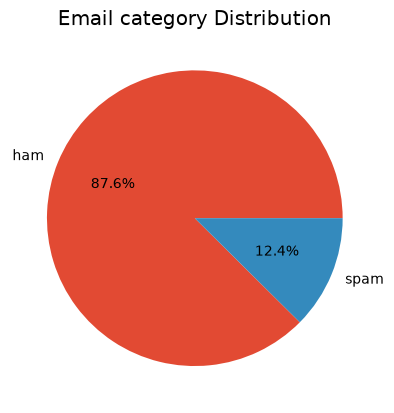

In [13]:
df["Category"].value_counts().plot(
    kind = "pie",
    autopct = "%1.1f%%"
)
plt.ylabel("")
plt.title("Email category Distribution")
plt.show()

In [14]:
print(df.columns.tolist())

['Category', 'Message']


In [15]:
df["Message_Length"] = df["Message"].str.len()

In [16]:
df["Message_Length"].describe()

count    5157.000000
mean       79.103936
std        58.382922
min         2.000000
25%        36.000000
50%        61.000000
75%       118.000000
max       910.000000
Name: Message_Length, dtype: float64

Text(0.5, 0, 'Characters')

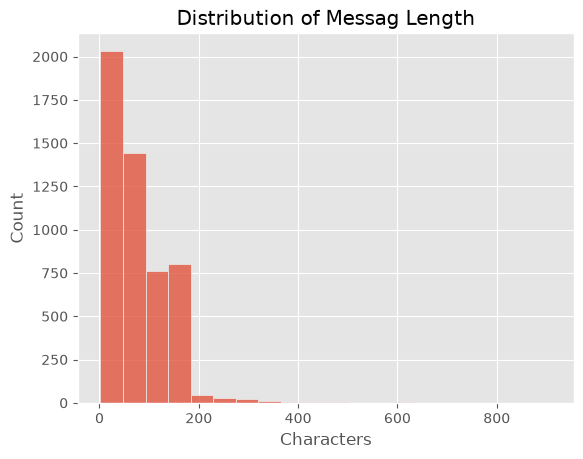

In [17]:
sns.histplot(df["Message_Length"] , bins = 20)
plt.title("Distribution of Messag Length")
plt.xlabel("Characters")

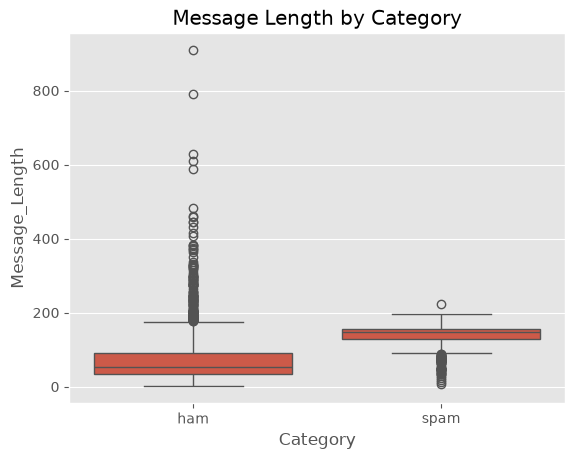

In [18]:
sns.boxplot(
    data = df,
    x = "Category",
    y = "Message_Length"

)
plt.title("Message Length by Category")
plt.show()

In [19]:
df.groupby("Category")["Message_Length"].mean()

Category
ham      70.869353
spam    137.118565
Name: Message_Length, dtype: float64

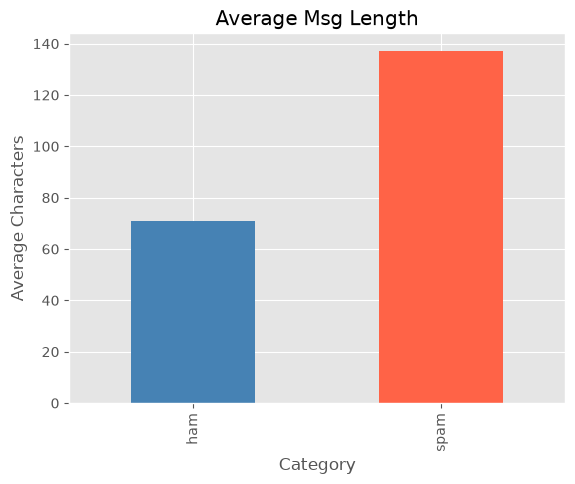

In [20]:
df.groupby("Category")["Message_Length"].mean().plot(
    kind = "bar",
    color = ["steelblue" , "tomato"]
)
plt.ylabel("Average Characters")
plt.title("Average Msg Length")
plt.show()

In [21]:
df.head()

,Category,Message,Message_Length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [22]:
df["Word_Count"] = df["Message"].apply(lambda x : len(x.split()))

In [23]:
df.head()

,Category,Message,Message_Length,Word_Count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


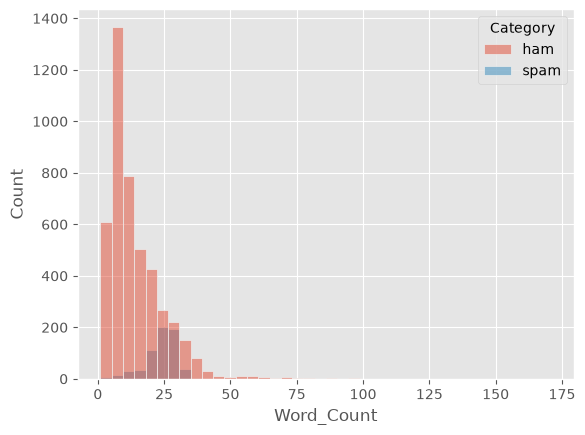

In [24]:
sns.histplot(
    data = df,
    x = "Word_Count",
    hue = "Category",
    bins = 40
)
plt.show()

In [25]:
df.groupby("Category")["Word_Count"].mean()

Category
ham     14.239814
spam    23.659906
Name: Word_Count, dtype: float64

In [26]:
df.nsmallest(10 , "Message_Length")

,Category,Message,Message_Length,Word_Count
1925,ham,Ok,2,1
3376,ham,:),2,1
261,ham,Yup,3,1
1612,ham,645,3,1
2182,ham,Ok.,3,1
287,ham,Ok..,4,1
2602,ham,Okie,4,1
5173,ham,U 2.,4,2
1273,ham,Ok...,5,1
4293,ham,G.W.R,5,1


In [27]:
df.nlargest(10,"Message_Length")

,Category,Message,Message_Length,Word_Count
1085,ham,For me the love should start with attraction.i...,910,171
1863,ham,The last thing i ever wanted to do was hurt yo...,790,162
2434,ham,Indians r poor but India is not a poor country...,629,109
1579,ham,How to Make a girl Happy? It's not at all diff...,611,103
2158,ham,Sad story of a Man - Last week was my b'day. M...,588,125
2380,ham,"Good evening Sir, hope you are having a nice d...",482,98
3017,ham,"&lt;#&gt; is fast approaching. So, Wish u a v...",461,66
1513,ham,"Hey sweet, I was wondering when you had a mome...",458,95
2370,ham,A Boy loved a gal. He propsd bt she didnt mind...,446,96
2408,ham,Solve d Case : A Man Was Found Murdered On &l...,444,71


In [28]:
df[df["Category"] == "spam"].sample(5)

,Category,Message,Message_Length,Word_Count
1714,spam,Hard LIVE 121 chat just 60p/min. Choose your g...,145,23
3382,spam,"complimentary 4 STAR Ibiza Holiday or £10,000 ...",149,21
54,spam,SMS. ac Sptv: The New Jersey Devils and the De...,120,22
2632,spam,"URGENT! Your mobile No 077xxx WON a £2,000 Bon...",153,26
1263,spam,"Hungry gay guys feeling hungry and up 4 it, no...",120,20


In [29]:
df[df["Category"] == "ham"].sample(5)

,Category,Message,Message_Length,Word_Count
1061,ham,I'm working technical support :)voice process....,63,7
1100,ham,Been up to ne thing interesting. Did you have ...,106,21
3695,ham,Ok im not sure what time i finish tomorrow but...,128,27
4667,ham,Not..tel software name..,24,3
4402,ham,Many times we lose our best ones bcoz we are,44,10


In [30]:
df["Category"] = df["Category"].map(
   { "ham": 0,
   "spam" :1
   }

)

In [31]:
df.head()

,Category,Message,Message_Length,Word_Count
0,0,"Go until jurong point, crazy.. Available only ...",111,20
1,0,Ok lar... Joking wif u oni...,29,6
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,0,U dun say so early hor... U c already then say...,49,11
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13


In [32]:
import warnings
warnings.filterwarnings("ignore")

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X = df["Message"]

In [35]:
y = df["Category"]

In [36]:
y.value_counts()

Category
0    4516
1     641
Name: count, dtype: int64

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words = "english",
    max_features = 5000,
    ngram_range = (1,2)
)

In [40]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [41]:
X_test_tfidf = tfidf.transform(X_test)

In [42]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RandomizedSearchCV

In [48]:
models = {

    "Naive Bayes": (
        MultinomialNB(),
        {
            "alpha": [0.1, 0.5, 1, 2, 5]
        }
    ),

    "Logistic Regression": (
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000
        ),
        {
            "C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "Linear SVM": (
        LinearSVC(
            class_weight="balanced"
        ),
        {
            "C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced"
        ),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    ),
    "Decision Tree" :(
        DecisionTreeClassifier(
            class_weight="balanced"
        ),
        {
            "max_depth" : [5,10,20,None],
            "min_samples_split":[2,5,10]



        }

    ),
    "Gradient Boosting":(
        GradientBoostingClassifier(),{
            "n_estimators":[100,200],
            "learning_rate": [0.01 , 0.05,0.1],
            "max_depth":[3,5]
        }
    ),
    "KNN" : (
        KNeighborsClassifier(),
        {
            "n_neighbors":[3,5,7,9]
        }

    )


}

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

In [ ]:
import numpy as np

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []
best_models = {}

for name, (model, params) in models.items():

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=10,
        cv=5,
        scoring="f1",
        n_jobs=-1,
        random_state=42
    )

    search.fit(X_train_tfidf, y_train)

    best_model = search.best_estimator_
    best_models[name] = best_model

    predictions = best_model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    try:
        if hasattr(best_model, "decision_function"):
            scores = best_model.decision_function(X_test_tfidf)
            auc = roc_auc_score(y_test, scores)

        elif hasattr(best_model, "predict_proba"):
            probabilities = best_model.predict_proba(X_test_tfidf)[:, 1]
            auc = roc_auc_score(y_test, probabilities)

        else:
            auc = np.nan

    except Exception:
        auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc,
        "Best Params": search.best_params_
    })
    

In [52]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Best Params
4,Decision Tree,0.288760,0.138015,0.838235,0.237006,0.530052,"{'min_samples_split': 5, 'max_depth': 20}"
2,Linear SVM,0.687016,0.154982,0.308824,0.206388,0.547084,{'C': 0.01}
1,Logistic Regression,0.686047,0.149254,0.294118,0.198020,0.546091,{'C': 0.1}
3,Random Forest,0.715116,0.140909,0.227941,0.174157,0.538648,"{'n_estimators': 100, 'min_samples_split': 10,..."
6,KNN,0.788760,0.140351,0.117647,0.128000,0.517988,{'n_neighbors': 3}
0,Naive Bayes,0.860465,0.250000,0.029412,0.052632,0.497903,{'alpha': 0.1}
5,Gradient Boosting,0.847868,0.080000,0.014706,0.024845,0.511481,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."


In [55]:
results_df.style.background_gradient(
    cmap="Greens",
    subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Best Params
4,Decision Tree,0.288760,0.138015,0.838235,0.237006,0.530052,"{'min_samples_split': 5, 'max_depth': 20}"
2,Linear SVM,0.687016,0.154982,0.308824,0.206388,0.547084,{'C': 0.01}
1,Logistic Regression,0.686047,0.149254,0.294118,0.198020,0.546091,{'C': 0.1}
3,Random Forest,0.715116,0.140909,0.227941,0.174157,0.538648,"{'n_estimators': 100, 'min_samples_split': 10, 'max_depth': None}"
6,KNN,0.788760,0.140351,0.117647,0.128000,0.517988,{'n_neighbors': 3}
0,Naive Bayes,0.860465,0.250000,0.029412,0.052632,0.497903,{'alpha': 0.1}
5,Gradient Boosting,0.847868,0.080000,0.014706,0.024845,0.511481,"{'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}"


In [56]:
best_model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [58]:
best_model_name = results_df.loc[results_df["F1"].idxmax(), "Model"]

best_model = best_models[best_model_name]

print("Best Model:", best_model_name)
print(best_model)

Best Model: Decision Tree
DecisionTreeClassifier(class_weight='balanced', max_depth=20,
                       min_samples_split=5)


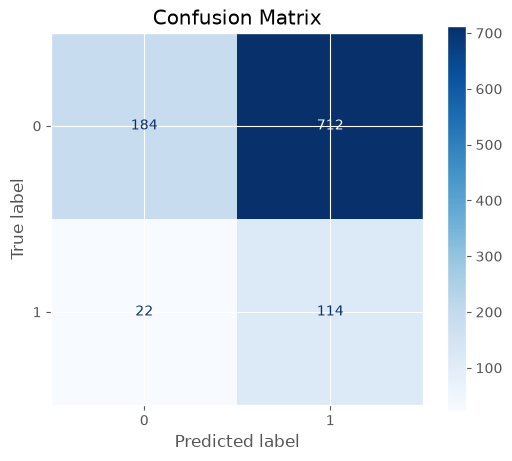

In [62]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_tfidf,
    y_test,
    cmap="Blues",
    ax=ax,
    values_format="d"
)

ax.set_title("Confusion Matrix")
plt.show()

In [67]:
emails = [
    "Congratulations! You won a free Iphone .Click here now .",
    "Hey, are we still meeting tomorrow at 10 AM ?",
    "URGENT! Claim your $1000 walmart gift card display"
]

emails_vectorized = tfidf.transform(emails)

predictions = best_model.predict(emails_vectorized)

for email , prediction in zip(emails , predictions):
    label = "Spam" if prediction == 1 else "Ham"
    print(label , ":" , "email")

Spam : email
Spam : email
Spam : email


In [70]:
emails = [
    "Congratulations! You have won a $500 Amazon gift card. Click here to claim your prize now.",
    
    "Hi Rahul, are we still meeting for lunch at 1 PM tomorrow?",
    
    "URGENT! Your account has won a $1,000 cash reward. Claim it before the offer expires.",
    
    "Hi team, please find the meeting agenda attached. We will discuss the project updates at 3 PM.",
    
    "You have been selected for an exclusive lottery prize of $10,000. Send your details to receive the money.",
    
    "Hey, can you please send me the notes from today's class? I missed the lecture.",
    
    "FREE iPhone 16 Pro! You are one of the lucky winners. Click the link below to claim your phone.",
    
    "Your electricity bill is due tomorrow. Please make the payment through the usual payment portal.",
    
    "WINNER! You have been chosen to receive a brand-new car. Call this number immediately to claim your prize.",
    
    "Hi, just checking if you received my email about the interview scheduled for Monday at 10 AM."
]

emails_vectorized = tfidf.transform(emails)

predictions = best_model.predict(emails_vectorized)

for email, prediction in zip(emails, predictions):
    label = "Spam" if prediction == 1 else "Ham"
    print(f"{label}: {email}")

emails_vectorized = tfidf.transform(emails)

predictions = best_model.predict(emails_vectorized)

for email, prediction in zip(emails, predictions):
    label = "Spam" if prediction == 1 else "Ham"
    print(f"Email :{email}")
    print(f"Prediction : {label}")
    print("-" * 70)


Spam: Congratulations! You have won a $500 Amazon gift card. Click here to claim your prize now.
Spam: Hi Rahul, are we still meeting for lunch at 1 PM tomorrow?
Spam: URGENT! Your account has won a $1,000 cash reward. Claim it before the offer expires.
Spam: Hi team, please find the meeting agenda attached. We will discuss the project updates at 3 PM.
Spam: You have been selected for an exclusive lottery prize of $10,000. Send your details to receive the money.
Spam: Hey, can you please send me the notes from today's class? I missed the lecture.
Spam: FREE iPhone 16 Pro! You are one of the lucky winners. Click the link below to claim your phone.
Spam: Your electricity bill is due tomorrow. Please make the payment through the usual payment portal.
Spam: WINNER! You have been chosen to receive a brand-new car. Call this number immediately to claim your prize.
Spam: Hi, just checking if you received my email about the interview scheduled for Monday at 10 AM.
Email :Congratulations! You h

In [71]:
import pickle 
with open("spam_classifier.pkl","wb") as file:
    pickle.dump(best_model , file)